# **FGD 6: Analisis Perbedaan Kinerja DenseNet121 dan Lightweight DenseNet (LWDN) pada Klasifikasi Citra Daun Tanaman Obat 🪴🌿**

## **CRISP-DM Phase 1: Business Understanding**
### *1. Tujuan Bisnis*
Proyek ini bertujuan untuk mengembangkan, membandingkan, dan mengevaluasi sistem klasifikasi jenis tanaman herbal berbasis citra daun menggunakan model Lightweight DenseNet (LWDN) sebagai arsitektur yang lebih ringan dengan DenseNet121 sebagai model acuan (baseline), sehingga identifikasi jenis tanaman herbal dapat dilakukan secara otomatis, cepat, dan konsisten. Hasil perbandingan dipakai untuk menentukan model yang paling layak menjadi dasar aplikasi identifikasi tanaman herbal bagi masyarakat, petani, dan pelaku industri obat tradisional.

###*2. Sasaran Bisnis*
* **Meningkatkan efisiensi identifikasi tanaman herbal**: Mengotomatisasi pengenalan jenis tanaman herbal dari citra daun sehingga mengurangi ketergantungan pada identifikasi manual oleh ahli botani atau tenaga berpengalaman.
* **Mengurangi risiko salah identifikasi:** salah mengenali tanaman herbal dapat memengaruhi kualitas dan keamanan penggunaannya.
* **Mendukung edukasi dan pelestarian pengetahuan tanaman obat**: Menjadi alat bantu belajar bagi masyarakat, pelajar, dan peneliti untuk mengenali berbagai jenis tanaman herbal.
* **Menjamin kualitas data:** dataset diperiksa terhadap duplikat, salah label, dan anomali citra (autoencoder) agar evaluasi model dapat dipercaya.
* **Menyediakan model yang layak untuk perangkat terbatas:** LWDN diharapkan lebih kecil dan cepat tanpa penurunan akurasi yang berarti, sehingga cocok untuk aplikasi web/mobile.

###*3. Kendala Bisnis*
* **Keterbatasan data** : Hanya 10 spesies/kelas dengan 350 citra per kelas, dari satu sumber dataset. Citra berupa daun tunggal berlatar putih, sehingga belum mewakili foto lapangan (latar alami, banyak daun, pencahayaan beragam). Hanya organ daun, tidak termasuk batang, bunga, atau buah
* **Sebaran kelas:** awalnya seimbang. Setelah cleansing jumlah per kelas bisa sedikit berbeda, sehingga dipakai *stratified split* dan augmentasi pada semua kelas untuk menyamakan jumlah data latih.
### *4. Kriteria Keberhasilan (Success Criteria)*

## CRISP-DM Phase 2: Data Understanding

Dataset awal berisi 3.500 citra daun dari 10 kelas. Eksperimen ini memakai hasil preparation yang sudah disimpan dalam Kaggle Input **FGD6 Handoff dan Checkpoint**: 4.000 citra train, 342 validation, dan 343 test. Jumlah train mencakup citra hasil augmentasi. Anggota split dan urutan kelas mengikuti handoff yang sama untuk kedua model.

### Library

TensorFlow digunakan untuk pipeline dan training. NumPy, pandas, scikit-learn, serta Matplotlib digunakan untuk menghitung dan menyajikan hasil.

In [1]:
# Memakai library yang tersedia pada lingkungan Kaggle.
import gc
import json
import platform
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.applications import densenet

## CRISP-DM Phase 3: Data Preparation

### Menggunakan handoff data

Citra RGB 224 × 224, label, split, dan konfigurasi augmentasi dibaca dari hasil preparation yang telah disepakati. Proses cleaning, pembagian data, serta pembuatan citra augmentasi tidak diulang pada eksperimen training ini.

In [2]:
# Membaca citra yang sudah disiapkan tanpa menyalin checkpoint eksperimen lama.
HANDOFF_DIR = Path("/kaggle/input/datasets/ouvvee/fgd6-handoff-dan-checkpoint/FGD6/handoff/20261028T104133_556236Z")
WORK_DIR = Path("/kaggle/working")
data_metadata = json.loads((HANDOFF_DIR / "metadata.json").read_text(encoding="utf-8"))
PREP_DIR = HANDOFF_DIR / "images"
CLASS_NAMES = data_metadata["classes"]
IMG_SIZE, BATCH, SEED = data_metadata["image_size"], data_metadata["batch"], data_metadata["seed"]
tf.keras.utils.set_random_seed(SEED)
augmenter = tf.keras.models.model_from_json(data_metadata["augmenter"])
assert len(CLASS_NAMES) == 10 and all(row[1] for row in data_metadata["checks"]), "Handoff data belum sesuai."

I0000 00:00:1793430964.551270      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793430964.555023      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


### Pipeline input

Gambar dibaca sesuai urutan kelas handoff. Data train diacak dan memakai augmentasi yang sama dengan pipeline sebelumnya. Normalisasi DenseNet dilakukan satu kali. Validation dan test tidak diacak atau diaugmentasi.

In [3]:
# Memakai pipeline handoff yang sama untuk kedua model.
AUTOTUNE = tf.data.AUTOTUNE # mengatur paralelisme otomatis

def load_base(split):
    ds = tf.keras.utils.image_dataset_from_directory(
        PREP_DIR / split, labels="inferred", label_mode="categorical",
        class_names=CLASS_NAMES, image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=None, shuffle=False)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)
    return ds.cache(), len(ds)

BASE, N_IMAGES = {}, {}
for s in ["train", "val", "test"]:
    BASE[s], N_IMAGES[s] = load_base(s)

def make_dataset(split, preprocess_fn, training=False):
    ds = BASE[split]
    if training:
        ds = ds.shuffle(N_IMAGES[split], seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


datasets = {"DenseNet121": {
    "train": make_dataset("train", densenet.preprocess_input, training=True),
    "val": make_dataset("val", densenet.preprocess_input),
    "test": make_dataset("test", densenet.preprocess_input),
}}
train_dataset = datasets["DenseNet121"]["train"]
val_dataset = datasets["DenseNet121"]["val"]
assert N_IMAGES == data_metadata["counts"], "Jumlah citra berbeda dari handoff."

Found 4000 files belonging to 10 classes.
Found 342 files belonging to 10 classes.
Found 343 files belonging to 10 classes.


## CRISP-DM Phase 4: Modeling — DenseNet-121

DenseNet-121 pretrained ImageNet dilatih dalam dua tahap: warm-up classifier, kemudian fine-tuning blok akhir. Kedua model memakai batas **10 epoch warm-up dan 25 epoch fine-tuning**, Adam dengan learning rate 0,001 dan 0,00001, serta early stopping dengan patience 3 dan 5. Batas epoch adalah maksimum; training dapat berhenti lebih awal ketika `val_loss` tidak membaik.

### Konfigurasi eksperimen

Setelan training, seed, identitas handoff, dan perangkat dicatat dalam folder run baru di `/kaggle/working/runs`. Checkpoint serta riwayat eksperimen lama tidak digunakan sebagai bobot awal.

In [4]:
# Menetapkan konfigurasi bersama dan folder hasil eksperimen baru.
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("Training memerlukan GPU pada Session options > Accelerator.")
gpu_details = tf.config.experimental.get_device_details(gpus[0])
precision_policy = "mixed_float16" if gpu_details.get("compute_capability", (0, 0)) >= (7, 0) else "float32"
tf.keras.mixed_precision.set_global_policy(precision_policy)
tf.keras.utils.set_random_seed(SEED)
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
experiment_dir = WORK_DIR / "runs" / run_id
run_dir = experiment_dir / "DenseNet121"
run_dir.mkdir(parents=True, exist_ok=False)
config = {
    "model": "DenseNet121",
    "weights": "imagenet",
    "handoff": str(HANDOFF_DIR),
    "dataset_file_id": data_metadata["dataset_file_id"],
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH,
    "classes": list(CLASS_NAMES),
    "train_images": N_IMAGES["train"],
    "validation_images": N_IMAGES["val"],
    "test_images": N_IMAGES["test"],
    "preprocessing": "RGB letterbox; augmentasi train dari handoff; densenet.preprocess_input satu kali",
    "class_weight": None,
    "dropout": 0.3,
    "loss": "categorical_crossentropy",
    "optimizer": "Adam",
    "warmup_epochs": 10,
    "warmup_learning_rate": 1e-3,
    "warmup_patience": 3,
    "finetune_epochs": 25,
    "finetune_learning_rate": 1e-5,
    "finetune_patience": 5,
    "finetune_block": "conv5_",
    "batchnorm_trainable": False,
    "checkpoint_monitor": "val_loss",
    "checkpoint_mode": "min",
    "precision_policy": precision_policy,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "gpu_name": gpu_details.get("device_name", gpus[0].name),
    "compute_capability": gpu_details.get("compute_capability"),
    "runtime": "Kaggle",
}
(run_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
shutil.copy2(HANDOFF_DIR / "metadata.json", experiment_dir / "handoff_metadata.json")
shutil.copy2(HANDOFF_DIR / "df_final.csv", experiment_dir / "handoff_manifest.csv")
(experiment_dir / "classes.json").write_text(json.dumps(CLASS_NAMES, indent=2), encoding="utf-8")

146

### Membangun DenseNet-121

Memuat backbone pretrained ImageNet tanpa classifier bawaan, lalu menambahkan global pooling, dropout, dan softmax untuk 10 kelas. Backbone dibekukan agar warm-up hanya melatih classifier baru.

In [5]:
# Membuat DenseNet-121 ImageNet dengan classifier 10 kelas.
base_model = tf.keras.applications.DenseNet121(
    include_top=False,  # Mengganti classifier ImageNet dengan kelas daun.
    weights=config["weights"],
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base_model.trainable = False  # Warm-up hanya melatih classifier baru.

# Preprocessing sudah dilakukan di pipeline Phase 3.
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
features = base_model(inputs, training=False)  # Statistik BatchNorm tetap beku saat fine-tuning.
features = tf.keras.layers.GlobalAveragePooling2D()(features)
features = tf.keras.layers.Dropout(config["dropout"])(features)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", dtype="float32")(features)
model = tf.keras.Model(inputs, outputs, name="herbal_densenet121")

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "herbal_densenet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,047,754 (26.89 MB)

 Trainable params: 10,250 (40.04 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

### Warm-up classifier

Melatih classifier di atas backbone beku menggunakan data train. `val_loss` menentukan checkpoint terbaik dan early stopping menghentikan training saat validation tidak membaik.

In [6]:
# Melatih classifier dengan backbone beku.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config["warmup_learning_rate"]),
    loss=config["loss"],
    metrics=["accuracy"],
)

# Menyimpan hasil warm-up berdasarkan validation.
warmup_checkpoint = run_dir / "warmup_best.keras"
warmup_start = time.perf_counter()
history_warmup = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=config["warmup_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(warmup_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=config["warmup_patience"]),
        tf.keras.callbacks.CSVLogger(str(run_dir / "warmup.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
warmup_seconds = time.perf_counter() - warmup_start

Epoch 1/10
  3/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.0938 - loss: 2.8067

I0000 00:00:1793431102.804531      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 ━━━━━━━━━━━━━━━━━━━━ 182s 422ms/step - accuracy: 0.5612 - loss: 1.3567 - val_accuracy: 0.8947 - val_loss: 0.5379
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 162ms/step - accuracy: 0.8263 - loss: 0.6310 - val_accuracy: 0.9269 - val_loss: 0.3308
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 159ms/step - accuracy: 0.8635 - loss: 0.4893 - val_accuracy: 0.9415 - val_loss: 0.2613
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 160ms/step - accuracy: 0.8755 - loss: 0.4214 - val_accuracy: 0.9503 - val_loss: 0.2243
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 161ms/step - accuracy: 0.8882 - loss: 0.3719 - val_accuracy: 0.9444 - val_loss: 0.2001
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 163ms/step - accuracy: 0.8990 - loss: 0.3393 - val_accuracy: 0.9415 - val_loss: 0.1948
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 163ms/step - accuracy: 0.9070 - loss: 0.3167 - val_accuracy: 0.9561 - val_loss: 0.1714
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 160ms/step - accuracy: 0.9145 - loss: 0.2926 - va

### Membuka blok akhir untuk fine-tuning

Memuat checkpoint warm-up terbaik, membuka blok `conv5_`, dan menjaga BatchNormalization tetap beku. Model di-compile ulang dengan learning rate yang lebih kecil.

In [7]:
# Memulai fine-tuning dari checkpoint warm-up terbaik.
model = tf.keras.models.load_model(warmup_checkpoint, compile=False)
base_model = model.get_layer("densenet121")
base_model.trainable = True
# Hanya conv5_ yang dibuka; statistik BatchNormalization tetap beku.
for layer in base_model.layers:
    layer.trainable = (
        layer.name.startswith(config["finetune_block"])
        and not isinstance(layer, tf.keras.layers.BatchNormalization)
    )

# Optimizer baru menggunakan learning rate lebih kecil.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config["finetune_learning_rate"]),
    loss=config["loss"],
    metrics=["accuracy"],
)

### Fine-tuning

Melatih classifier bersama blok `conv5_` dengan data train dan validation. Checkpoint terbaik dipilih dari `val_loss`; log epoch dan durasi disimpan untuk menelusuri eksperimen.

In [8]:
# Menyesuaikan conv5_ dan classifier dengan learning rate kecil.
# Checkpoint terpisah menjaga hasil warm-up tetap tersedia.
finetune_checkpoint = run_dir / "finetune_best.keras"
finetune_start = time.perf_counter()
history_finetune = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=config["finetune_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(finetune_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=config["finetune_patience"]),
        tf.keras.callbacks.CSVLogger(str(run_dir / "finetune.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
finetune_seconds = time.perf_counter() - finetune_start

Epoch 1/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 334ms/step - accuracy: 0.9290 - loss: 0.2293 - val_accuracy: 0.9620 - val_loss: 0.1262
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 164ms/step - accuracy: 0.9315 - loss: 0.2020 - val_accuracy: 0.9649 - val_loss: 0.1206
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.9348 - loss: 0.1955 - val_accuracy: 0.9649 - val_loss: 0.1097
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 148ms/step - accuracy: 0.9388 - loss: 0.1905 - val_accuracy: 0.9649 - val_loss: 0.1105
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 160ms/step - accuracy: 0.9455 - loss: 0.1656 - val_accuracy: 0.9708 - val_loss: 0.1030
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.9438 - loss: 0.1629 - val_accuracy: 0.9708 - val_loss: 0.1002
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 149ms/step - accuracy: 0.9463 - loss: 0.1492 - val_accuracy: 0.9708 - val_loss: 0.1005
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 161ms/step - accuracy: 0.9567 - loss: 0

### Memilih checkpoint DenseNet-121

Checkpoint warm-up dan fine-tuning dibandingkan berdasarkan `val_loss` minimum. Jika nilainya sama, checkpoint warm-up dipilih. Model terpilih dan waktu training disimpan untuk evaluasi bersama LWDN.

In [9]:
# Memilih checkpoint terbaik dari dua tahap training.
candidates = []
for stage in ("warmup", "finetune"):
    log = pd.read_csv(run_dir / f"{stage}.csv")
    assert not log.empty and np.isfinite(log[["loss", "val_loss"]].to_numpy()).all(), "Training menghasilkan log yang tidak valid."
    best = log.loc[log["val_loss"].idxmin()]
    candidates.append({
        "stage": stage,
        "epoch_in_stage": int(best["epoch"]) + 1,
        "val_loss": float(best["val_loss"]),
        "checkpoint": str(run_dir / f"{stage}_best.keras"),
    })
selection = min(candidates, key=lambda item: item["val_loss"])
selected_model_path = Path(selection["checkpoint"])
model = tf.keras.models.load_model(selected_model_path, compile=False)
model.save(run_dir / "inference.keras")
selection.update(
    parameters=model.count_params(),
    warmup_seconds=warmup_seconds,
    finetune_seconds=finetune_seconds,
    total_training_seconds=warmup_seconds + finetune_seconds,
    test_evaluated=False,
)
(run_dir / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
print(f"DenseNet-121: {selection['stage']} | epoch {selection['epoch_in_stage']} | val_loss {selection['val_loss']:.4f}")
experiments = {"DenseNet121": {"run_dir": run_dir, "selection": selection}}

DenseNet-121: finetune | epoch 24 | val_loss 0.0724


## CRISP-DM Phase 4: Modeling Part II — Lightweight DenseNet

LWDN memakai adaptasi dua cabang dari [Dheeraj & Chand (2024)](https://doi.org/10.1007/s41348-024-00915-z) yang sudah digunakan pada notebook ini. Setiap cabang DenseNet pretrained ImageNet dipotong pada `conv3_block4_concat`. Fitur kedua cabang digabung, lalu diproses oleh global pooling dan classifier Dense 512 → Dense 256 → softmax 10 kelas, dengan dropout 0,3.

Training memakai data, preprocessing, seed, precision, optimizer, learning rate, batas epoch, dan early stopping yang sama dengan DenseNet-121. Warm-up melatih classifier dengan kedua backbone beku. Fine-tuning membuka blok akhir `conv3_` pada kedua cabang dan menjaga BatchNormalization tetap beku. Blok ini menjadi blok akhir LWDN karena bagian `conv5_` sudah dipangkas. Hasil dipilih melalui validation; test digunakan setelah kedua checkpoint dipilih.

### Konfigurasi LWDN

Setelan training disalin langsung dari DenseNet-121. LWDN memulai eksperimen baru dari bobot ImageNet dengan folder hasil tersendiri.

In [10]:
# Menggunakan setelan training baseline dan mengulang state acak untuk LWDN.
del model, base_model, inputs, features, outputs, history_warmup, history_finetune
tf.keras.backend.clear_session()
gc.collect()
tf.keras.utils.set_random_seed(config["seed"])
tf.keras.mixed_precision.set_global_policy(config["precision_policy"])
augmenter = tf.keras.models.model_from_json(data_metadata["augmenter"])
lwdn_train_dataset = make_dataset("train", densenet.preprocess_input, training=True)
lwdn_val_dataset = val_dataset
lwdn_config = {
    **config,
    "model": "LWDN_adapted",
    "paper_doi": "10.1007/s41348-024-00915-z",
    "branch_cutoff": "conv3_block4_concat",
    "branches": 2,
    "fusion_axis": -1,
    "head_units": [512, 256],
    "finetune_block": "conv3_",
    "finetune_branches": ["lwdn_branch_1", "lwdn_branch_2"],
}
lwdn_run_dir = experiment_dir / "LWDN"
lwdn_run_dir.mkdir(exist_ok=False)
(lwdn_run_dir / "config.json").write_text(json.dumps(lwdn_config, indent=2), encoding="utf-8")

1496

### Membangun LWDN

Dua backbone memiliki bobot yang terpisah dan dibekukan selama warm-up. Gabungan fiturnya digunakan untuk memprediksi 10 kelas daun.

In [11]:
# Mempertahankan struktur dua cabang dan head 512–256 dari paper.
lwdn_branches = []
for branch_number in (1, 2):
    lwdn_pretrained = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=lwdn_config["weights"],
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    lwdn_branch = tf.keras.Model(
        lwdn_pretrained.input,
        lwdn_pretrained.get_layer(lwdn_config["branch_cutoff"]).output,
        name=f"lwdn_branch_{branch_number}",
    )
    lwdn_branch.trainable = False
    lwdn_branches.append(lwdn_branch)
    del lwdn_pretrained

lwdn_inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
lwdn_features = tf.keras.layers.Concatenate(axis=lwdn_config["fusion_axis"], name="feature_fusion")(
    [branch(lwdn_inputs, training=False) for branch in lwdn_branches]
)
lwdn_features = tf.keras.layers.GlobalAveragePooling2D()(lwdn_features)
for units in lwdn_config["head_units"]:
    lwdn_features = tf.keras.layers.Dense(units, activation="relu")(lwdn_features)
    lwdn_features = tf.keras.layers.Dropout(lwdn_config["dropout"])(lwdn_features)
lwdn_outputs = tf.keras.layers.Dense(10, activation="softmax", dtype="float32")(lwdn_features)
lwdn_model = tf.keras.Model(lwdn_inputs, lwdn_outputs, name="herbal_lwdn_adapted")

lwdn_model.summary()

Model: "herbal_lwdn_adapted"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lwdn_branch_1       │ (None, 28, 28,    │    624,192 │ input_layer_2[0]… │
│ (Functional)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lwdn_branch_2       │ (None, 28, 28,    │    624,192 │ input_layer_2[0]… │
│ (Functional)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 28, 28,    │          0 │ lwdn_branch_1[0]… │
│ (Concatenate)       │ 512)              │            │ lwdn_branch_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ feature_fusion[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    262,656 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,328 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 10)        │      2,570 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,644,938 (6.27 MB)

 Trainable params: 396,554 (1.51 MB)

 Non-trainable params: 1,248,384 (4.76 MB)

### Warm-up classifier LWDN

Classifier dilatih maksimal 10 epoch dengan learning rate 0,001. Checkpoint dengan `val_loss` terendah disimpan dan menjadi titik awal fine-tuning.

In [12]:
# Melatih classifier dengan protokol warm-up yang sama.
lwdn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lwdn_config["warmup_learning_rate"]),
    loss=lwdn_config["loss"],
    metrics=["accuracy"],
)
lwdn_warmup_checkpoint = lwdn_run_dir / "warmup_best.keras"
lwdn_warmup_start = time.perf_counter()
lwdn_history_warmup = lwdn_model.fit(
    lwdn_train_dataset,
    validation_data=lwdn_val_dataset,
    epochs=lwdn_config["warmup_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(lwdn_warmup_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=lwdn_config["warmup_patience"],
        ),
        tf.keras.callbacks.CSVLogger(str(lwdn_run_dir / "warmup.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
lwdn_warmup_seconds = time.perf_counter() - lwdn_warmup_start

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 199ms/step - accuracy: 0.1758 - loss: 2.2039 - val_accuracy: 0.2485 - val_loss: 2.0248
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 149ms/step - accuracy: 0.2607 - loss: 1.9798 - val_accuracy: 0.2456 - val_loss: 1.8919
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 150ms/step - accuracy: 0.3215 - loss: 1.8059 - val_accuracy: 0.3860 - val_loss: 1.7300
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 150ms/step - accuracy: 0.3715 - loss: 1.6877 - val_accuracy: 0.4737 - val_loss: 1.5520
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 152ms/step - accuracy: 0.3985 - loss: 1.6132 - val_accuracy: 0.4620 - val_loss: 1.4743
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 149ms/step - accuracy: 0.4320 - loss: 1.5465 - val_accuracy: 0.4620 - val_loss: 1.5021
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.4565 - loss: 1.4699 - val_accuracy: 0.5409 - val_loss: 1.3477
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.4787 - loss: 1

### Membuka blok akhir LWDN

Model dimuat dari hasil warm-up terbaik. Blok `conv3_` pada kedua cabang dibuka, BatchNormalization tetap beku, dan Adam dibuat ulang dengan learning rate 0,00001.

In [13]:
# Menggunakan strategi blok terakhir; LWDN yang dipangkas tidak memiliki conv5_.
lwdn_model = tf.keras.models.load_model(lwdn_warmup_checkpoint, compile=False)
lwdn_branches = [lwdn_model.get_layer(name) for name in lwdn_config["finetune_branches"]]
for lwdn_branch in lwdn_branches:
    lwdn_branch.trainable = True
    for layer in lwdn_branch.layers:
        layer.trainable = (
            layer.name.startswith(lwdn_config["finetune_block"])
            and not isinstance(layer, tf.keras.layers.BatchNormalization)
        )
    assert lwdn_branch.trainable_weights, "Tidak ada bobot backbone yang dibuka."
    assert all(
        not layer.trainable
        for layer in lwdn_branch.layers
        if isinstance(layer, tf.keras.layers.BatchNormalization)
    )
    assert all(layer.name.startswith("conv3_") for layer in lwdn_branch.layers if layer.trainable)

lwdn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lwdn_config["finetune_learning_rate"]),
    loss=lwdn_config["loss"],
    metrics=["accuracy"],
)

### Fine-tuning LWDN

Blok akhir dan classifier dilatih maksimal 25 epoch. Early stopping memakai patience 5, sama dengan DenseNet-121. Checkpoint terbaik, log tiap epoch, dan durasi training disimpan.

In [14]:
# Menyesuaikan blok akhir dan classifier dari checkpoint warm-up terbaik.
lwdn_finetune_checkpoint = lwdn_run_dir / "finetune_best.keras"
lwdn_finetune_start = time.perf_counter()
lwdn_history_finetune = lwdn_model.fit(
    lwdn_train_dataset,
    validation_data=lwdn_val_dataset,
    epochs=lwdn_config["finetune_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(lwdn_finetune_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=lwdn_config["finetune_patience"]),
        tf.keras.callbacks.CSVLogger(str(lwdn_run_dir / "finetune.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
lwdn_finetune_seconds = time.perf_counter() - lwdn_finetune_start

Epoch 1/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 44s 202ms/step - accuracy: 0.5543 - loss: 1.2384 - val_accuracy: 0.6404 - val_loss: 1.1156
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.5560 - loss: 1.2153 - val_accuracy: 0.6082 - val_loss: 1.0981
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 147ms/step - accuracy: 0.5675 - loss: 1.1953 - val_accuracy: 0.6082 - val_loss: 1.1013
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 148ms/step - accuracy: 0.5748 - loss: 1.1865 - val_accuracy: 0.5965 - val_loss: 1.1007
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.5773 - loss: 1.1600 - val_accuracy: 0.6140 - val_loss: 1.0654
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 151ms/step - accuracy: 0.5773 - loss: 1.1612 - val_accuracy: 0.6170 - val_loss: 1.0562
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.5995 - loss: 1.1347 - val_accuracy: 0.6082 - val_loss: 1.0384
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.5910 - loss: 1

### Memilih checkpoint LWDN

Aturan pemilihan mengikuti DenseNet-121: `val_loss` minimum dari warm-up dan fine-tuning. Penambahan kesempatan training tidak menjamin akurasi meningkat; hasil validation menunjukkan perubahan yang benar-benar terjadi.

In [15]:
# Memilih checkpoint terbaik dari dua tahap training.
candidates = []
for stage in ("warmup", "finetune"):
    log = pd.read_csv(lwdn_run_dir / f"{stage}.csv")
    assert not log.empty and np.isfinite(log[["loss", "val_loss"]].to_numpy()).all(), "Training menghasilkan log yang tidak valid."
    best = log.loc[log["val_loss"].idxmin()]
    candidates.append({
        "stage": stage,
        "epoch_in_stage": int(best["epoch"]) + 1,
        "val_loss": float(best["val_loss"]),
        "checkpoint": str(lwdn_run_dir / f"{stage}_best.keras"),
    })
lwdn_selection = min(candidates, key=lambda item: item["val_loss"])
lwdn_selected_model_path = Path(lwdn_selection["checkpoint"])
lwdn_model = tf.keras.models.load_model(lwdn_selected_model_path, compile=False)
lwdn_model.save(lwdn_run_dir / "inference.keras")
lwdn_selection.update(
    parameters=lwdn_model.count_params(),
    warmup_seconds=lwdn_warmup_seconds,
    finetune_seconds=lwdn_finetune_seconds,
    total_training_seconds=lwdn_warmup_seconds + lwdn_finetune_seconds,
    test_evaluated=False,
)
(lwdn_run_dir / "selection.json").write_text(json.dumps(lwdn_selection, indent=2), encoding="utf-8")
print(f"LWDN: {lwdn_selection['stage']} | epoch {lwdn_selection['epoch_in_stage']} | val_loss {lwdn_selection['val_loss']:.4f}")
experiments["LWDN"] = {"run_dir": lwdn_run_dir, "selection": lwdn_selection}

LWDN: finetune | epoch 24 | val_loss 0.9166


## CRISP-DM Phase 5: Evaluation

### Hasil validation kedua model

Checkpoint terpilih dinilai pada seluruh data validation. Accuracy, precision, recall, F1-score macro, hasil per kelas, dan confusion matrix disimpan untuk kedua model.

,precision,recall,f1-score,support
Belimbing Wuluh,0.944400,0.971400,0.957700,35.000000
Jambu Biji,0.945900,1.000000,0.972200,35.000000
Jeruk Nipis,0.966700,0.906200,0.935500,32.000000
Kemangi,0.941200,0.914300,0.927500,35.000000
Lidah Buaya,0.972200,1.000000,0.985900,35.000000
Nangka,1.000000,0.941200,0.969700,34.000000
Pandan,1.000000,0.971400,0.985500,35.000000
Pepaya,1.000000,1.000000,1.000000,32.000000
Seledri,1.000000,1.000000,1.000000,35.000000
Sirih,0.944400,1.000000,0.971400,34.000000


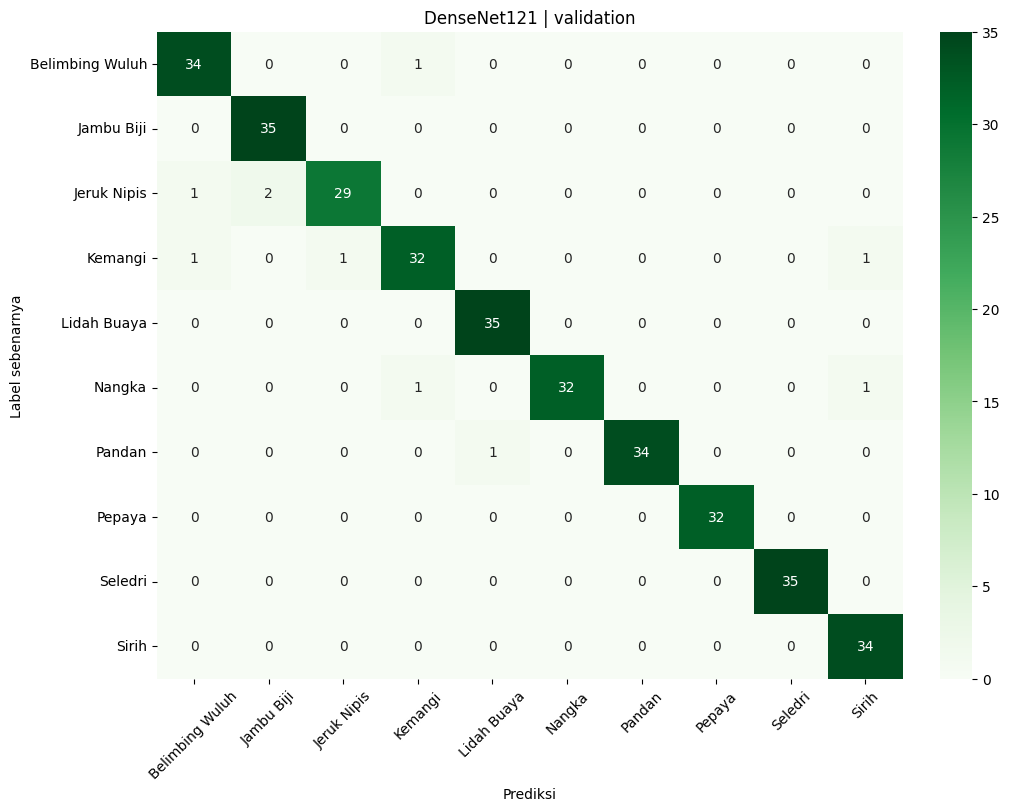

,precision,recall,f1-score,support
Belimbing Wuluh,0.680000,0.485700,0.566700,35.000000
Jambu Biji,0.410300,0.914300,0.566400,35.000000
Jeruk Nipis,0.653800,0.531200,0.586200,32.000000
Kemangi,0.567600,0.600000,0.583300,35.000000
Lidah Buaya,0.918900,0.971400,0.944400,35.000000
Nangka,0.631600,0.352900,0.452800,34.000000
Pandan,0.918900,0.971400,0.944400,35.000000
Pepaya,0.774200,0.750000,0.761900,32.000000
Seledri,0.812500,0.742900,0.776100,35.000000
Sirih,0.400000,0.235300,0.296300,34.000000


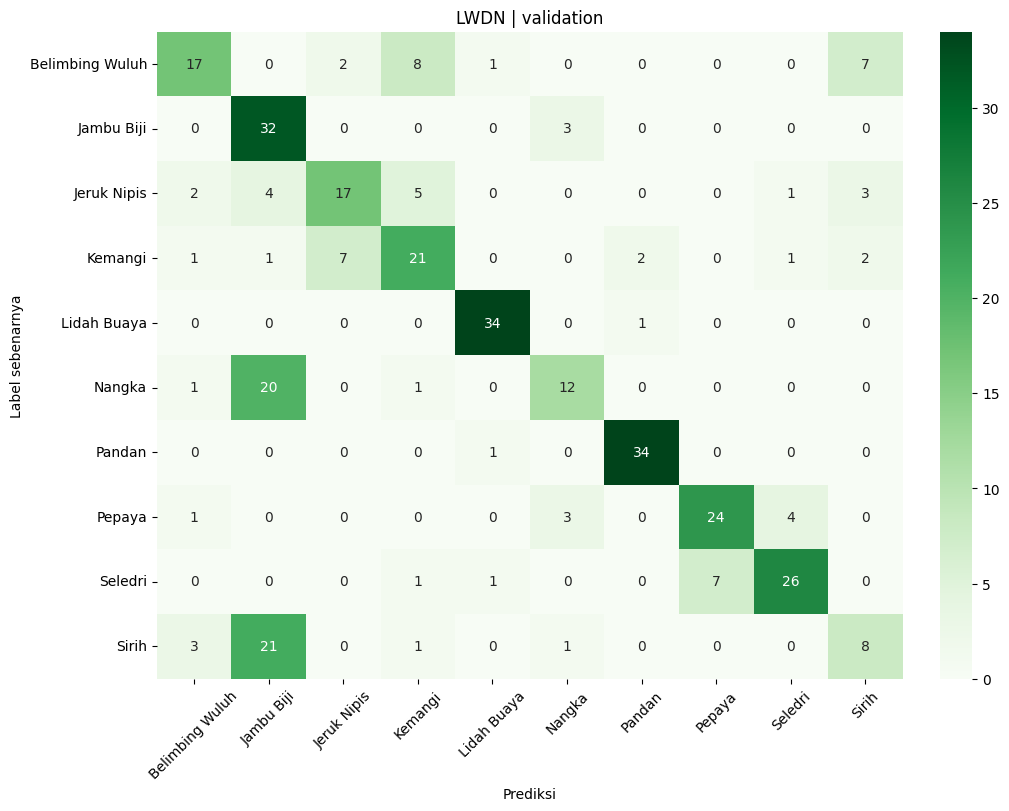

,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
DenseNet121,0.9708,0.9715,0.9705,0.9706
LWDN,0.6579,0.6768,0.6555,0.6479


In [16]:
# Menghitung metrik dari prediksi checkpoint terpilih pada split yang sama.
validation_rows = []
for name, experiment in experiments.items():
    result_dir = experiment["run_dir"]
    eval_model = tf.keras.models.load_model(result_dir / "inference.keras", compile=False)
    labels, probabilities = [], []
    for images, batch_labels in datasets["DenseNet121"]["val"]:
        labels.append(batch_labels.numpy().argmax(axis=1))
        probabilities.append(eval_model(images, training=False).numpy())
    y_true, y_prob = np.concatenate(labels), np.concatenate(probabilities)
    assert len(y_true) == N_IMAGES["val"] and np.isfinite(y_prob).all()
    y_pred = y_prob.argmax(axis=1)
    np.savez_compressed(result_dir / "validation_predictions.npz", y_true=y_true, y_pred=y_pred, probabilities=y_prob)
    report = classification_report(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T
    report_df.to_csv(result_dir / "validation_metrics.csv")
    display(report_df.round(4).style.set_caption(name + " | validation"))
    validation_rows.append({"model": name, "accuracy": report["accuracy"], "precision_macro": report["macro avg"]["precision"], "recall_macro": report["macro avg"]["recall"], "f1_macro": report["macro avg"]["f1-score"]})
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(result_dir / "validation_confusion.csv")
    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(xlabel="Prediksi", ylabel="Label sebenarnya", title=name + " | validation")
    ax.tick_params(axis="x", rotation=45)
    fig.savefig(result_dir / "validation_confusion.png", dpi=150)
    plt.show()
    plt.close(fig)
    del eval_model
validation_results = pd.DataFrame(validation_rows).set_index("model")
validation_results.to_csv(experiment_dir / "validation_summary.csv")
display(validation_results.round(4))

### Kurva pembelajaran

Kurva loss dan akurasi memperlihatkan perkembangan train dan validation untuk kedua model. Garis vertikal menandai pergantian warm-up ke fine-tuning. Titik menandai checkpoint terpilih menurut `val_loss`.

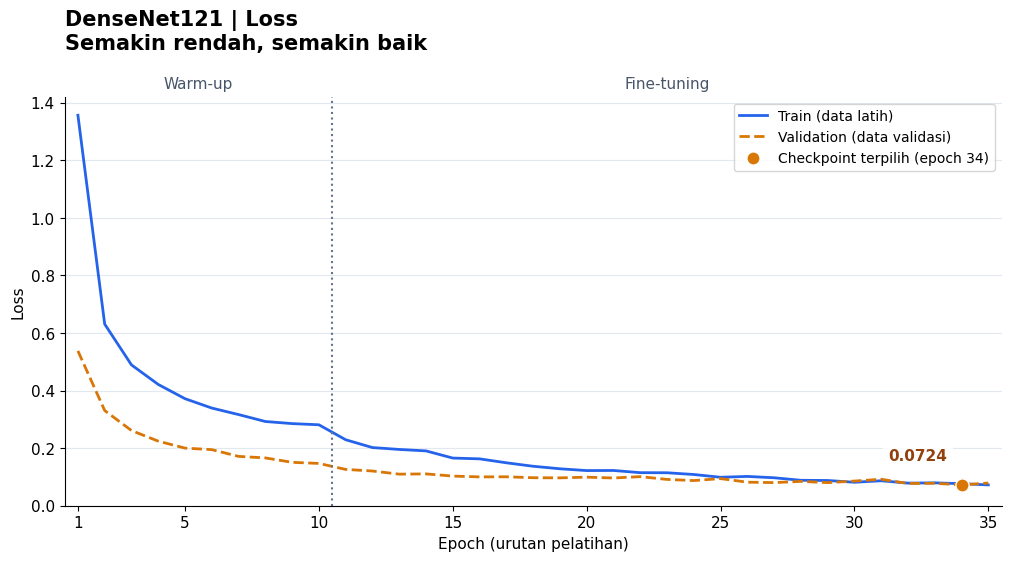

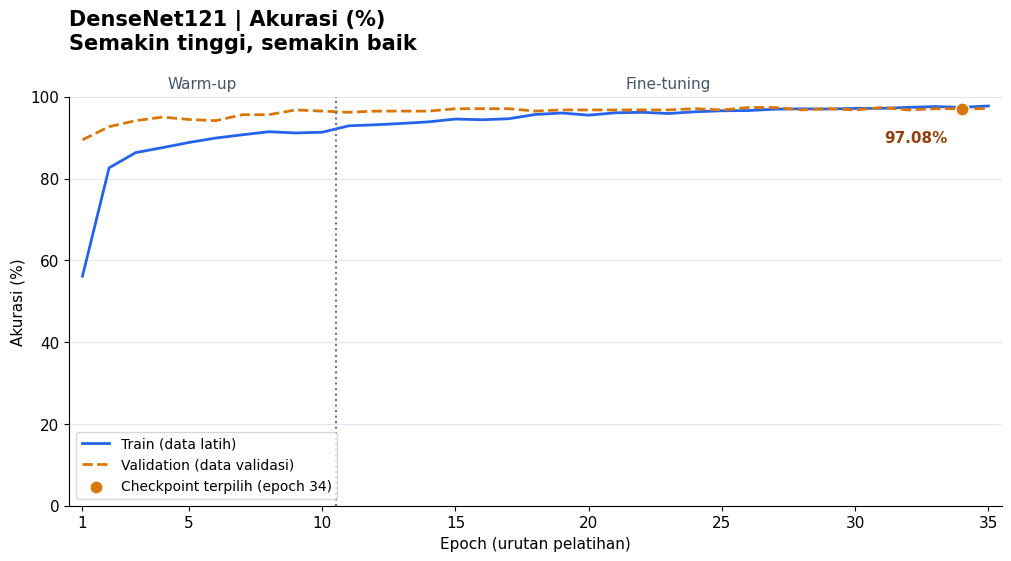

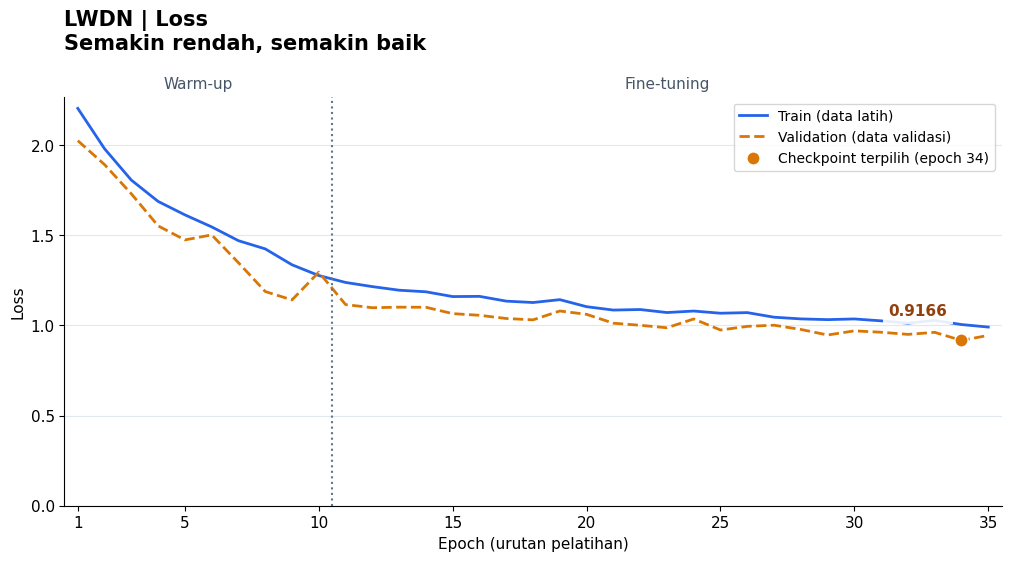

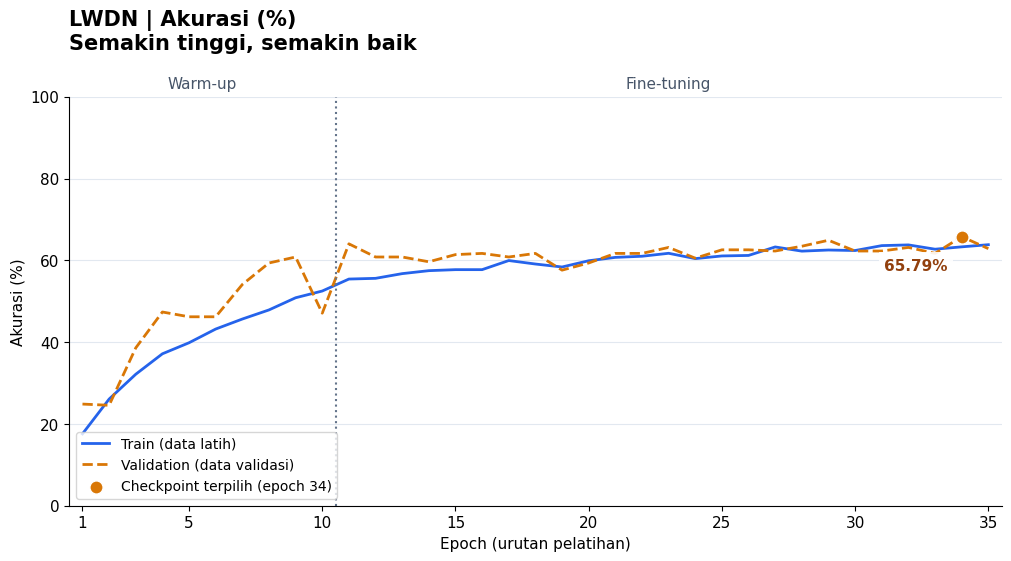

In [17]:
# Membaca log kedua model tanpa mengulang training.
for name, experiment in experiments.items():
    result_dir = experiment["run_dir"]
    # Membuat ulang kurva dari log tanpa menjalankan prediksi validation.
    warmup_log = pd.read_csv(result_dir / "warmup.csv")
    finetune_log = pd.read_csv(result_dir / "finetune.csv")
    training_log = pd.concat([warmup_log, finetune_log], ignore_index=True)
    assert len(warmup_log) > 0 and len(finetune_log) > 0, "Log kedua tahap harus tersedia."
    assert np.isfinite(training_log[["loss", "val_loss", "accuracy", "val_accuracy"]]).all().all(), "Log berisi nilai tidak valid."
    epochs = np.arange(1, len(training_log) + 1)
    warmup_epochs = len(warmup_log)
    selected_index = int(training_log["val_loss"].argmin())
    selected_global_epoch = selected_index + 1

    # Setiap metrik menjadi satu gambar; warna dan skala konsisten.
    with plt.rc_context({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 11}):
        for metric, title, direction, scale in (
            ("loss", "Loss", "Semakin rendah, semakin baik", 1),
            ("accuracy", "Akurasi (%)", "Semakin tinggi, semakin baik", 100),
        ):
            train_values = training_log[metric].to_numpy() * scale
            val_values = training_log["val_" + metric].to_numpy() * scale
            fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
            ax.plot(epochs, train_values, color="#2563EB", linewidth=2, label="Train (data latih)")
            ax.plot(epochs, val_values, color="#D97706", linewidth=2, linestyle="--", label="Validation (data validasi)")
            ax.axvline(warmup_epochs + 0.5, color="#64748B", linestyle=":", linewidth=1.5)
            ax.text((warmup_epochs + 1) / 2, 1.02, "Warm-up", transform=ax.get_xaxis_transform(), ha="center", color="#475569")
            ax.text((warmup_epochs + 1 + len(epochs)) / 2, 1.02, "Fine-tuning", transform=ax.get_xaxis_transform(), ha="center", color="#475569")

            # Penanda mengikuti val_loss minimum, termasuk pada grafik akurasi.
            ax.scatter(selected_global_epoch, val_values[selected_index], color="#D97706", edgecolors="white", s=90, zorder=5,
                       label=f"Checkpoint terpilih (epoch {selected_global_epoch})")
            selected_label = f"{val_values[selected_index]:.2f}%" if metric == "accuracy" else f"{val_values[selected_index]:.4f}"
            ax.annotate(selected_label, (selected_global_epoch, val_values[selected_index]),
                        xytext=(-10, -24) if metric == "accuracy" else (-10, 18),
                        textcoords="offset points", ha="right", fontweight="bold", color="#92400E",
                        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
            ax.set(xlabel="Epoch (urutan pelatihan)", ylabel=title,
                   xlim=(0.5, len(epochs) + 0.5))
            ax.set_title(f"{name} | {title}\n{direction}", loc="left", pad=34, fontweight="bold")
            ax.set_xticks(sorted(set([1, *range(5, len(epochs) + 1, 5), len(epochs)])))
            if metric == "accuracy":
                ax.set_ylim(0, 100)
            else:
                ax.set_ylim(bottom=0)
            ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
            ax.grid(axis="x", visible=False)
            ax.spines[["top", "right"]].set_visible(False)
            ax.legend(loc="lower left" if metric == "accuracy" else "upper right", frameon=True, fontsize=10)
            fig.savefig(result_dir / f"learning_curve_{metric}.png", dpi=200, bbox_inches="tight", facecolor="white")
            plt.show()
            plt.close(fig)

### Evaluasi test berpasangan

Setelah kedua checkpoint dipilih melalui validation, seluruh citra test dinilai sekali untuk setiap model. Kedua model memakai urutan citra dan label yang sama. Hasil test menjadi laporan akhir dan tidak digunakan untuk mengganti konfigurasi atau checkpoint.

,precision,recall,f1-score,support
Belimbing Wuluh,0.971400,0.971400,0.971400,35.000000
Jambu Biji,1.000000,1.000000,1.000000,35.000000
Jeruk Nipis,1.000000,0.969700,0.984600,33.000000
Kemangi,0.970600,0.942900,0.956500,35.000000
Lidah Buaya,1.000000,1.000000,1.000000,35.000000
Nangka,0.972200,1.000000,0.985900,35.000000
Pandan,1.000000,1.000000,1.000000,35.000000
Pepaya,1.000000,1.000000,1.000000,31.000000
Seledri,1.000000,1.000000,1.000000,35.000000
Sirih,0.971400,1.000000,0.985500,34.000000


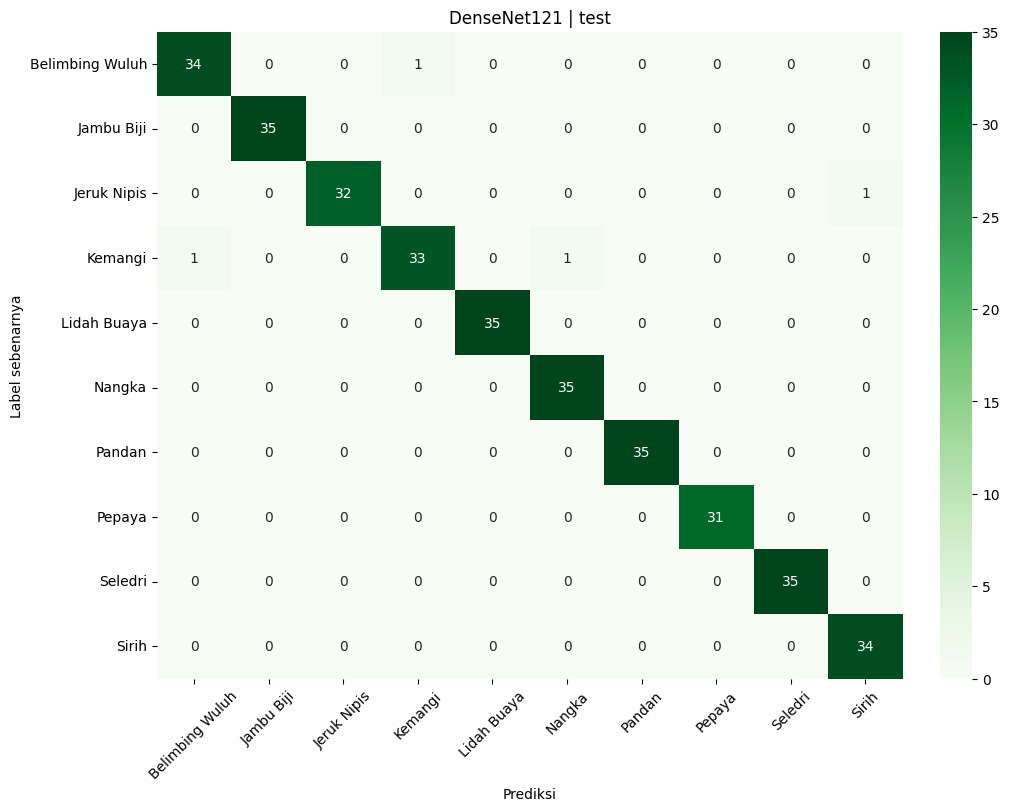

,precision,recall,f1-score,support
Belimbing Wuluh,0.607100,0.485700,0.539700,35.000000
Jambu Biji,0.422500,0.857100,0.566000,35.000000
Jeruk Nipis,0.785700,0.666700,0.721300,33.000000
Kemangi,0.605300,0.657100,0.630100,35.000000
Lidah Buaya,0.775000,0.885700,0.826700,35.000000
Nangka,0.772700,0.485700,0.596500,35.000000
Pandan,0.820500,0.914300,0.864900,35.000000
Pepaya,0.783800,0.935500,0.852900,31.000000
Seledri,0.931000,0.771400,0.843800,35.000000
Sirih,0.727300,0.235300,0.355600,34.000000


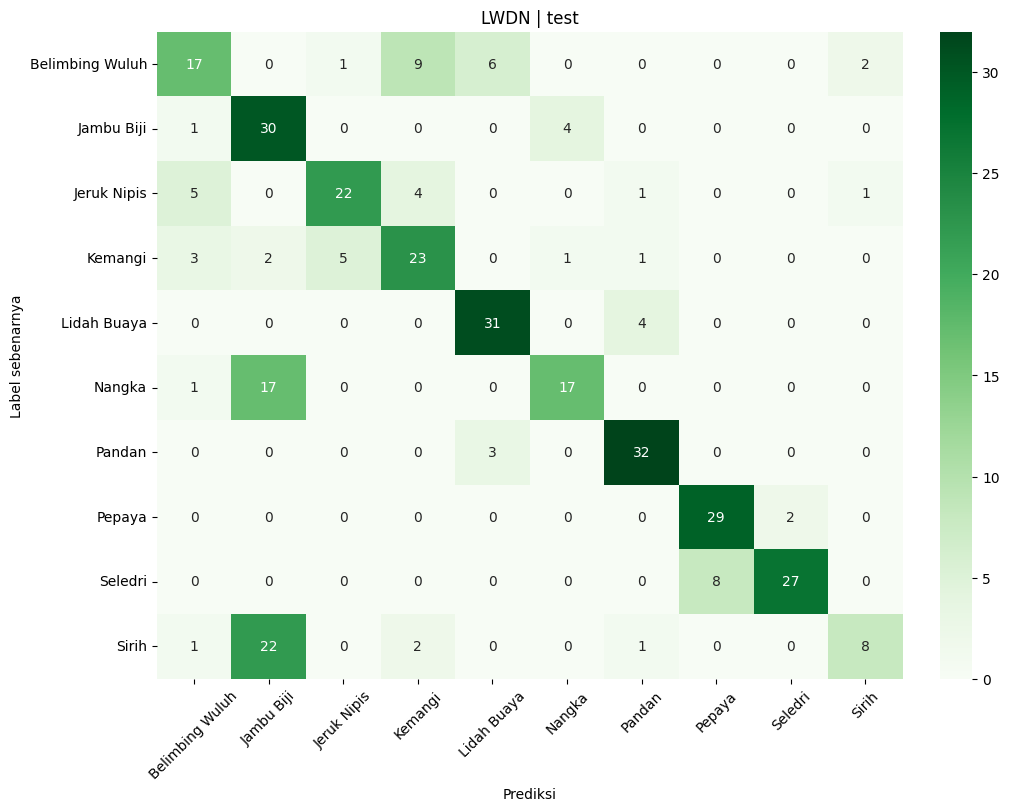

,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
DenseNet121,0.9883,0.9886,0.9884,0.9884
LWDN,0.6880,0.7231,0.6895,0.6797


In [18]:
# Menghitung metrik dari prediksi checkpoint terpilih pada split yang sama.
test_rows = []
for name, experiment in experiments.items():
    result_dir = experiment["run_dir"]
    eval_model = tf.keras.models.load_model(result_dir / "inference.keras", compile=False)
    labels, probabilities = [], []
    for images, batch_labels in datasets["DenseNet121"]["test"]:
        labels.append(batch_labels.numpy().argmax(axis=1))
        probabilities.append(eval_model(images, training=False).numpy())
    y_true, y_prob = np.concatenate(labels), np.concatenate(probabilities)
    assert len(y_true) == N_IMAGES["test"] and np.isfinite(y_prob).all()
    y_pred = y_prob.argmax(axis=1)
    np.savez_compressed(result_dir / "test_predictions.npz", y_true=y_true, y_pred=y_pred, probabilities=y_prob)
    report = classification_report(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T
    report_df.to_csv(result_dir / "test_metrics.csv")
    display(report_df.round(4).style.set_caption(name + " | test"))
    test_rows.append({"model": name, "accuracy": report["accuracy"], "precision_macro": report["macro avg"]["precision"], "recall_macro": report["macro avg"]["recall"], "f1_macro": report["macro avg"]["f1-score"]})
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(result_dir / "test_confusion.csv")
    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(xlabel="Prediksi", ylabel="Label sebenarnya", title=name + " | test")
    ax.tick_params(axis="x", rotation=45)
    fig.savefig(result_dir / "test_confusion.png", dpi=150)
    plt.show()
    plt.close(fig)
    experiment["selection"]["test_evaluated"] = True
    (result_dir / "selection.json").write_text(json.dumps(experiment["selection"], indent=2), encoding="utf-8")
    del eval_model
test_results = pd.DataFrame(test_rows).set_index("model")
test_results.to_csv(experiment_dir / "test_summary.csv")
display(test_results.round(4))

### Efisiensi model

Jumlah parameter, ukuran model tanpa optimizer, dan durasi kedua tahap training dicatat. Latensi inferensi diukur pada GPU yang sama, batch 1, dengan 10 pemanasan dan 100 pengulangan. Pengukuran mencakup pemanggilan graph TensorFlow dan pengambilan hasil ke CPU; pembacaan citra serta preprocessing dikeluarkan dari waktu pengukuran.

In [19]:
# Mengukur kedua model dengan input validation dan protokol yang sama.
benchmark_input = next(iter(val_dataset))[0][:1]
efficiency_rows = []
for name, experiment in experiments.items():
    result_dir = experiment["run_dir"]
    with tf.device("/GPU:0"):
        benchmark_model = tf.keras.models.load_model(result_dir / "inference.keras", compile=False)
        predict = tf.function(benchmark_model, jit_compile=False)
        for _ in range(10):
            predict(benchmark_input, training=False).numpy()
        latency_ms = []
        for _ in range(100):
            started = time.perf_counter()
            predict(benchmark_input, training=False).numpy()
            latency_ms.append((time.perf_counter() - started) * 1000)
    efficiency_rows.append({
        "model": name,
        "parameters": benchmark_model.count_params(),
        "model_size_mib": (result_dir / "inference.keras").stat().st_size / 1024**2,
        "training_seconds": experiment["selection"]["total_training_seconds"],
        "inference_median_ms": float(np.median(latency_ms)),
    })
    (result_dir / "latency.json").write_text(json.dumps({"device": "/GPU:0", "gpu": config["gpu_name"], "precision": config["precision_policy"], "batch": 1, "warmup": 10, "samples_ms": latency_ms, "preprocessing_included": False}, indent=2), encoding="utf-8")
    del benchmark_model, predict
efficiency_results = pd.DataFrame(efficiency_rows).set_index("model")
efficiency_results.to_csv(experiment_dir / "efficiency.csv")
display(efficiency_results.round(4))

,parameters,model_size_mib,training_seconds,inference_median_ms
model,,,,
DenseNet121,7047754,28.3148,936.3250,16.5397
LWDN,1644938,6.8345,726.3664,6.2275


### Perbedaan kinerja dan kesalahan kelas

Selisih dihitung sebagai **LWDN − DenseNet-121**. Nilai positif berarti LWDN lebih tinggi, sedangkan nilai negatif berarti LWDN lebih rendah. Metrik klasifikasi dinyatakan dalam poin persentase; ukuran, waktu, dan latensi memakai satuannya masing-masing. Recall dan F1 per kelas serta pasangan kelas yang paling sering tertukar membantu menjelaskan perbedaan hasil.

In [20]:
# Membandingkan hasil yang diukur pada eksperimen yang sama.
differences = []
for split, results in (("validation", validation_results), ("test", test_results)):
    for metric in results.columns:
        dense_value, lwdn_value = results.loc["DenseNet121", metric] * 100, results.loc["LWDN", metric] * 100
        differences.append({"split": split, "metric": metric, "DenseNet121": dense_value, "LWDN": lwdn_value, "LWDN_minus_DenseNet121": lwdn_value - dense_value, "unit": "poin persentase"})
for metric, unit in (("parameters", "parameter"), ("model_size_mib", "MiB"), ("training_seconds", "detik"), ("inference_median_ms", "ms/citra")):
    dense_value, lwdn_value = efficiency_results.loc["DenseNet121", metric], efficiency_results.loc["LWDN", metric]
    differences.append({"split": "efisiensi", "metric": metric, "DenseNet121": dense_value, "LWDN": lwdn_value, "LWDN_minus_DenseNet121": lwdn_value - dense_value, "unit": unit})
comparison = pd.DataFrame(differences)
comparison.to_csv(experiment_dir / "comparison.csv", index=False)
display(comparison.round(4))
per_class = []
for name, experiment in experiments.items():
    report = pd.read_csv(experiment["run_dir"] / "test_metrics.csv", index_col=0)
    per_class.append(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]].add_prefix(name + "_"))
    matrix = pd.read_csv(experiment["run_dir"] / "test_confusion.csv", index_col=0).to_numpy()
    np.fill_diagonal(matrix, 0)
    pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(matrix[i, j])) for i, j in np.ndindex(matrix.shape) if matrix[i, j] > 0]
    display(pd.DataFrame(sorted(pairs, key=lambda item: item[2], reverse=True)[:5], columns=["kelas_asli", "prediksi", "jumlah"]).style.set_caption(name + " | kesalahan test terbanyak"))
class_comparison = pd.concat(per_class, axis=1)
for metric in ("precision", "recall", "f1-score"):
    class_comparison[metric + "_difference_pp"] = 100 * (class_comparison["LWDN_" + metric] - class_comparison["DenseNet121_" + metric])
class_comparison.to_csv(experiment_dir / "per_class_comparison.csv")
display(class_comparison.round(4))

,split,metric,DenseNet121,LWDN,LWDN_minus_DenseNet121,unit
0,validation,accuracy,9.707600e+01,6.578950e+01,-3.128650e+01,poin persentase
1,validation,precision_macro,9.714900e+01,6.767780e+01,-2.947120e+01,poin persentase
2,validation,recall_macro,9.704570e+01,6.555200e+01,-3.149370e+01,poin persentase
3,validation,f1_macro,9.705540e+01,6.478620e+01,-3.226920e+01,poin persentase
4,test,accuracy,9.883380e+01,6.880470e+01,-3.002920e+01,poin persentase
5,test,precision_macro,9.885670e+01,7.230990e+01,-2.654680e+01,poin persentase
6,test,recall_macro,9.883980e+01,6.894590e+01,-2.989400e+01,poin persentase
7,test,f1_macro,9.883990e+01,6.797440e+01,-3.086550e+01,poin persentase
8,efisiensi,parameters,7.047754e+06,1.644938e+06,-5.402816e+06,parameter
9,efisiensi,model_size_mib,2.831480e+01,6.834500e+00,-2.148030e+01,MiB


,kelas_asli,prediksi,jumlah
0,Belimbing Wuluh,Kemangi,1
1,Jeruk Nipis,Sirih,1
2,Kemangi,Belimbing Wuluh,1
3,Kemangi,Nangka,1


,kelas_asli,prediksi,jumlah
0,Sirih,Jambu Biji,22
1,Nangka,Jambu Biji,17
2,Belimbing Wuluh,Kemangi,9
3,Seledri,Pepaya,8
4,Belimbing Wuluh,Lidah Buaya,6


,DenseNet121_precision,DenseNet121_recall,DenseNet121_f1-score,LWDN_precision,LWDN_recall,LWDN_f1-score,precision_difference_pp,recall_difference_pp,f1-score_difference_pp
Belimbing Wuluh,0.9714,0.9714,0.9714,0.6071,0.4857,0.5397,-36.4286,-48.5714,-43.1746
Jambu Biji,1.0000,1.0000,1.0000,0.4225,0.8571,0.5660,-57.7465,-14.2857,-43.3962
Jeruk Nipis,1.0000,0.9697,0.9846,0.7857,0.6667,0.7213,-21.4286,-30.3030,-26.3304
Kemangi,0.9706,0.9429,0.9565,0.6053,0.6571,0.6301,-36.5325,-28.5714,-32.6385
Lidah Buaya,1.0000,1.0000,1.0000,0.7750,0.8857,0.8267,-22.5000,-11.4286,-17.3333
Nangka,0.9722,1.0000,0.9859,0.7727,0.4857,0.5965,-19.9495,-51.4286,-38.9424
Pandan,1.0000,1.0000,1.0000,0.8205,0.9143,0.8649,-17.9487,-8.5714,-13.5135
Pepaya,1.0000,1.0000,1.0000,0.7838,0.9355,0.8529,-21.6216,-6.4516,-14.7059
Seledri,1.0000,1.0000,1.0000,0.9310,0.7714,0.8438,-6.8966,-22.8571,-15.6250
Sirih,0.9714,1.0000,0.9855,0.7273,0.2353,0.3556,-24.4156,-76.4706,-62.9952


### Catatan hasil eksperimen

Penambahan epoch memberikan kesempatan belajar yang sama, tetapi tidak menjamin LWDN mencapai akurasi DenseNet-121. Kesimpulan mengikuti metrik, kurva validation, kesalahan tiap kelas, dan biaya komputasi yang diukur. Eksperimen satu seed serta citra daun dengan latar terkendali belum menunjukkan kemampuan pada foto lapangan.

Seluruh artefak eksperimen berada dalam `/kaggle/working/runs`. Penyimpanan versi Kaggle beserta output mempertahankan checkpoint, konfigurasi, log, grafik, dan tabel hasil setelah sesi berakhir.